# Homework 7 - Extra Practice

Austin Oliver | GitHub: awoliver335 | USC ID: 1949137702

Optional work: Homework 7 parts 1(b)(v)-(vi), and ISLR (2nd ed.) 12.6 exercises 1 and 3-13. Exercise 2 is in [the main notebook](Oliver_Austin_HW7.ipynb).
Run this notebook from the repository folder. It uses local data and seed **552**, and runs independently of the main notebook.
The textbook's R exercises are implemented in Python.

In [1]:
# pip install -r requirements.txt
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (multilabel_confusion_matrix, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 552
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

## 1(b)(v). Classifier chains

A classifier chain uses earlier target labels as predictors for later targets. I use the order **Family → Genus → Species**, chosen from the taxonomy before evaluating the test set. This can exploit label dependence, but an early mistake can propagate through the chain.

The usual [classifier chain](https://scikit-learn.org/1.7/modules/generated/sklearn.multioutput.ClassifierChain.html) uses binary outputs. Here I implement its multiclass extension: one one-versus-rest RBF SVM per target, adding one-hot indicators for earlier targets. Training uses earlier **true training labels**; prediction uses only earlier **predictions**. The one-hot encoding avoids treating category names as ordered numbers.

I reuse the main notebook's seed-552 70/30 split and training-selected settings: RBF $C=10,\gamma=0.1$ for all targets; unweighted and weighted L1 $C=(10,10,1)$. I refit those three baselines to obtain predictions and decision scores. The chain uses the RBF settings as a fixed comparison, without a new hyperparameter or chain-order search. Scaling is fitted only on the training MFCCs; appended indicators remain 0/1.

In [2]:
frog = pd.read_csv('data/Frogs_MFCCs.csv')
targets = ['Family', 'Genus', 'Species']
X = frog.filter(regex=r'^MFCCs_')
y = frog[targets]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
classes = {target: np.sort(y_train[target].unique()) for target in targets}
predictions, scores = {}, {}
assert len(X_train) == 5036 and len(X_test) == 2159
assert set(X_train.index).isdisjoint(X_test.index)

for name in ['RBF', 'L1', 'Weighted L1']:
    pred_columns, score_columns = [], []
    for target, C in zip(targets, [10, 10, 1]):
        model = (OneVsRestClassifier(SVC(C=10, gamma=0.1)) if name == 'RBF'
                 else LinearSVC(C=C, penalty='l1', dual=False,
                                class_weight='balanced' if name == 'Weighted L1' else None,
                                tol=1e-3, max_iter=50000, random_state=SEED))
        with threadpool_limits(limits=1):
            model.fit(X_train_s, y_train[target])
        assert np.array_equal(model.classes_, classes[target])
        pred_columns.append(model.predict(X_test_s))
        score_columns.append(model.decision_function(X_test_s))
    predictions[name] = np.column_stack(pred_columns)
    scores[name] = np.column_stack(score_columns)

chain_train, chain_test = X_train_s.copy(), X_test_s.copy()
chain_predictions, chain_scores = [], []
for target in targets:
    model = OneVsRestClassifier(SVC(C=10, gamma=0.1))
    with threadpool_limits(limits=1):
        model.fit(chain_train, y_train[target])
    pred = model.predict(chain_test)
    chain_predictions.append(pred)
    chain_scores.append(model.decision_function(chain_test))
    assert np.array_equal(model.classes_, classes[target])
    train_indicators = y_train[target].to_numpy()[:, None] == classes[target]
    test_indicators = pred[:, None] == classes[target]
    chain_train = np.column_stack([chain_train, train_indicators])
    chain_test = np.column_stack([chain_test, test_indicators])
predictions['RBF chain'] = np.column_stack(chain_predictions)
scores['RBF chain'] = np.column_stack(chain_scores)

agreement = pd.DataFrame({name: {
    'Exact match': (pred == y_test.to_numpy()).all(axis=1).mean(),
    'Hamming loss': (pred != y_test.to_numpy()).mean(),
    'Hamming score': (pred == y_test.to_numpy()).mean()
} for name, pred in predictions.items()}).T
assert np.allclose(agreement.loc[['RBF', 'L1', 'Weighted L1'], 'Exact match'],
                   [0.985178, 0.916165, 0.904122], atol=1e-6, rtol=0)
display(agreement.round(6))
delta = agreement.loc['RBF chain', 'Exact match'] - agreement.loc['RBF', 'Exact match']
display(Markdown(f'The chain changes exact-match accuracy by **{100*delta:+.2f} percentage points** '
                 'relative to independent RBF models on this split. This is a comparison of one fixed '
                 'chain order; it does not establish that chains are generally better.'))

,Exact match,Hamming loss,Hamming score
RBF,0.985178,0.011271,0.988729
L1,0.916165,0.053111,0.946889
Weighted L1,0.904122,0.058824,0.941176
RBF chain,0.985178,0.011579,0.988421


The chain changes exact-match accuracy by **+0.00 percentage points** relative to independent RBF models on this split. This is a comparison of one fixed chain order; it does not establish that chains are generally better.

## 1(b)(vi). Confusion matrices, precision, recall, ROC and AUC

I expand the three categorical targets into **22 typed indicators** (4 families, 8 genera, 10 species). Each sample has exactly three positives. For each indicator, the [confusion matrix](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.multilabel_confusion_matrix.html), with actual classes in rows and predictions in columns, is
$$\begin{pmatrix}TN&FP\\FN&TP\end{pmatrix},\qquad
\mathrm{precision}=\frac{TP}{TP+FP},\qquad
\mathrm{recall}=\frac{TP}{TP+FN}.$$

**Macro** averages give each indicator equal weight; **micro** averages pool their counts; **sample** averages first score each observation. Here micro and sample precision/recall equal the categorical Hamming score because both the true and predicted label sets have size three. This differs from computing Hamming loss over all 22 bits. Undefined precision is reported as zero. See the [precision averaging definitions](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.precision_score.html).

An ROC curve varies a decision-score threshold and plots $TPR=TP/(TP+FN)$ against $FPR=FP/(FP+TN)$. [AUC](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.roc_auc_score.html) is the area under that curve (0.5 for chance ranking, 1 for perfect ranking). I use continuous SVM margins, not predicted labels. Macro AUC averages the 22 one-versus-rest AUCs. Micro AUC pools all margins; its value depends on how comparable different classifiers' score scales are, so macro AUC is the primary ranking summary.

In [3]:
indicator_names = [f'{target[0]}: {c}' for target in targets for c in classes[target]]
truth_bits = np.column_stack([
    y_test[target].to_numpy()[:, None] == classes[target] for target in targets])
metric_rows, detail_tables, roc_points = [], {}, {}
for name, pred in predictions.items():
    pred_bits = np.column_stack([
        pred[:, j, None] == classes[target] for j, target in enumerate(targets)])
    matrices = multilabel_confusion_matrix(truth_bits, pred_bits)
    tn, fp, fn, tp = matrices.reshape(-1, 4).T
    detail_tables[name] = pd.DataFrame({
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Precision': precision_score(truth_bits, pred_bits, average=None, zero_division=0),
        'Recall': recall_score(truth_bits, pred_bits, average=None, zero_division=0),
        'AUC': roc_auc_score(truth_bits, scores[name], average=None)
    }, index=pd.Index(indicator_names, name='Indicator'))
    row = {'Model': name}
    for average in ['micro', 'macro', 'samples']:
        row[f'P {average}'] = precision_score(truth_bits, pred_bits, average=average, zero_division=0)
        row[f'R {average}'] = recall_score(truth_bits, pred_bits, average=average, zero_division=0)
    row['AUC macro'] = roc_auc_score(truth_bits, scores[name], average='macro')
    row['AUC micro'] = roc_auc_score(truth_bits, scores[name], average='micro')
    metric_rows.append(row)
    roc_points[name] = [roc_curve(truth_bits[:, j], scores[name][:, j])
                        for j in range(truth_bits.shape[1])]
    assert np.all(matrices.sum(axis=(1, 2)) == len(y_test))
    assert np.isclose(row['P micro'], agreement.loc[name, 'Hamming score'])
    assert np.isclose(row['R samples'], row['P micro'])
display(pd.DataFrame(metric_rows).set_index('Model').round(4))

,P micro,R micro,P macro,R macro,P samples,R samples,AUC macro,AUC micro
Model,,,,,,,,
RBF,0.9887,0.9887,0.9788,0.9622,0.9887,0.9887,0.9985,0.9994
L1,0.9469,0.9469,0.8824,0.8317,0.9469,0.9469,0.9795,0.9913
Weighted L1,0.9412,0.9412,0.8393,0.8989,0.9412,0.9412,0.9810,0.9895
RBF chain,0.9884,0.9884,0.9759,0.9611,0.9884,0.9884,0.9989,0.9995


The tables below contain every class's 2×2 confusion matrix as TN, FP, FN, TP, followed by its precision, recall and AUC. F/G/S identify Family/Genus/Species.

### RBF: class-level results

In [4]:
display(detail_tables['RBF'].round(4))

,TN,FP,FN,TP,Precision,Recall,AUC
Indicator,,,,,,,
F: Bufonidae,2137,2,2,18,0.9000,0.9000,0.9971
F: Dendrobatidae,2000,1,0,158,0.9937,1.0000,1.0000
F: Hylidae,1493,17,2,647,0.9744,0.9969,0.9994
F: Leptodactylidae,826,1,17,1315,0.9992,0.9872,0.9997
G: Adenomera,908,3,9,1239,0.9976,0.9928,0.9997
G: Ameerega,2000,1,0,158,0.9937,1.0000,1.0000
G: Dendropsophus,2067,3,3,86,0.9663,0.9663,0.9998
G: Hypsiboas,1656,17,3,483,0.9660,0.9938,0.9997
G: Leptodactylus,2075,0,3,81,1.0000,0.9643,0.9913


### L1: class-level results

In [5]:
display(detail_tables['L1'].round(4))

,TN,FP,FN,TP,Precision,Recall,AUC
Indicator,,,,,,,
F: Bufonidae,2136,3,20,0,0.0000,0.0000,0.9490
F: Dendrobatidae,1978,23,15,143,0.8614,0.9051,0.9934
F: Hylidae,1450,60,69,580,0.9062,0.8937,0.9600
F: Leptodactylidae,766,61,43,1289,0.9548,0.9677,0.9785
G: Adenomera,872,39,21,1227,0.9692,0.9832,0.9853
G: Ameerega,1986,15,6,152,0.9102,0.9620,0.9934
G: Dendropsophus,2063,7,34,55,0.8871,0.6180,0.9659
G: Hypsiboas,1638,35,11,475,0.9314,0.9774,0.9807
G: Leptodactylus,2073,2,11,73,0.9733,0.8690,0.9847


### Weighted L1: class-level results

In [6]:
display(detail_tables['Weighted L1'].round(4))

,TN,FP,FN,TP,Precision,Recall,AUC
Indicator,,,,,,,
F: Bufonidae,2108,31,2,18,0.3673,0.9000,0.9520
F: Dendrobatidae,1956,45,8,150,0.7692,0.9494,0.9942
F: Hylidae,1471,39,79,570,0.9360,0.8783,0.9595
F: Leptodactylidae,779,48,74,1258,0.9632,0.9444,0.9791
G: Adenomera,888,23,45,1203,0.9812,0.9639,0.9857
G: Ameerega,1975,26,9,149,0.8514,0.9430,0.9938
G: Dendropsophus,2055,15,26,63,0.8077,0.7079,0.9703
G: Hypsiboas,1657,16,19,467,0.9669,0.9609,0.9800
G: Leptodactylus,2067,8,8,76,0.9048,0.9048,0.9837


### RBF chain: class-level results

In [7]:
display(detail_tables['RBF chain'].round(4))

,TN,FP,FN,TP,Precision,Recall,AUC
Indicator,,,,,,,
F: Bufonidae,2137,2,2,18,0.9000,0.9000,0.9971
F: Dendrobatidae,2000,1,0,158,0.9937,1.0000,1.0000
F: Hylidae,1493,17,2,647,0.9744,0.9969,0.9994
F: Leptodactylidae,826,1,17,1315,0.9992,0.9872,0.9997
G: Adenomera,908,3,9,1239,0.9976,0.9928,0.9996
G: Ameerega,2000,1,0,158,0.9937,1.0000,1.0000
G: Dendropsophus,2067,3,3,86,0.9663,0.9663,0.9997
G: Hypsiboas,1656,17,3,483,0.9660,0.9938,0.9997
G: Leptodactylus,2075,0,4,80,1.0000,0.9524,0.9951


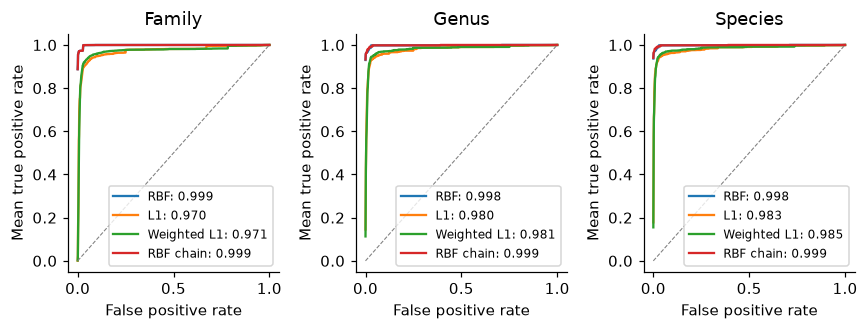

These are macro ROC curves within each target, with mean class AUCs in the legends. The per-class tables show whether strong aggregate performance hides rare-class errors. Class weighting changes precision and recall together; improved minority recall does not necessarily improve exact match. As in the main assignment, random row splitting permits calls from the same recording in both sets.

In [8]:
grid = np.linspace(0, 1, 1001)
fig, axes = plt.subplots(1, 3, figsize=(8, 3.1))
start = 0
for ax, target in zip(axes, targets):
    indices = range(start, start + len(classes[target]))
    for name in predictions:
        mean_tpr = np.mean([np.interp(grid, *roc_points[name][j][:2])
                            for j in indices], axis=0)
        mean_auc = detail_tables[name].iloc[list(indices)]['AUC'].mean()
        ax.plot(grid, mean_tpr, label=f'{name}: {mean_auc:.3f}')
    ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=0.7)
    ax.set(title=target, xlabel='False positive rate', ylabel='Mean true positive rate')
    ax.legend(fontsize=8, loc='lower right')
    start += len(classes[target])
plt.tight_layout()
plt.show()
display(Markdown('These are macro ROC curves within each target, with mean class AUCs in the legends. '
                 'The per-class tables show whether strong aggregate performance hides rare-class errors. '
                 'Class weighting changes precision and recall together; improved minority recall does not '
                 'necessarily improve exact match. As in the main assignment, random row splitting permits '
                 'calls from the same recording in both sets.'))

## ISLR 12.6: remaining exercises

Exercises 1 and 3-13 from *An Introduction to Statistical Learning*, 2nd edition, pp. 546-550. Exercise 2 is part of the required homework.

### ISLR 12.6.1: the K-means objective

**(a)** For a cluster $C$ of size $m$, let $\bar x_j=m^{-1}\sum_{i\in C}x_{ij}$. Expanding the squares gives
$$\begin{aligned}
\frac1m\sum_{i,i'\in C}(x_{ij}-x_{i'j})^2
&=2\sum_{i\in C}x_{ij}^2-\frac2m\left(\sum_{i\in C}x_{ij}\right)^2\\
&=2\sum_{i\in C}(x_{ij}-\bar x_j)^2.
\end{aligned}$$
Summing over features proves (12.18), so the objective (12.17) is twice the within-cluster sum of squares.

**(b)** For fixed assignments, each cluster mean minimizes its squared-error sum. For fixed means, assigning each point to its nearest mean cannot increase that sum. Recomputing the means can only reduce it further. Therefore each iteration is non-increasing (strictly decreasing unless the improvement is zero). It stops at a stable assignment, which need not be the global minimum.


### ISLR 12.6.3: manual K-means

**(a)-(f)** I use the six given points and random initial labels with seed 552. The table records the initial and updated assignments; the following update is unchanged. Centroids are calculated from the labels in that row; reassignment uses Euclidean distance. The final groups are $\{1,2,3\}$ and $\{4,5,6\}$, with centroids $(2/3,11/3)$ and $(5,1)$.


,Step,Labels (observations 1-6),Centroid 1,Centroid 2
0,0,1 1 2 1 1 2,"(3.25, 2.5)","(2.0, 2.0)"
1,1,2 2 2 1 1 1,"(5.0, 1.0)","(0.667, 3.667)"


Next assignment is unchanged: 2 2 2 1 1 1


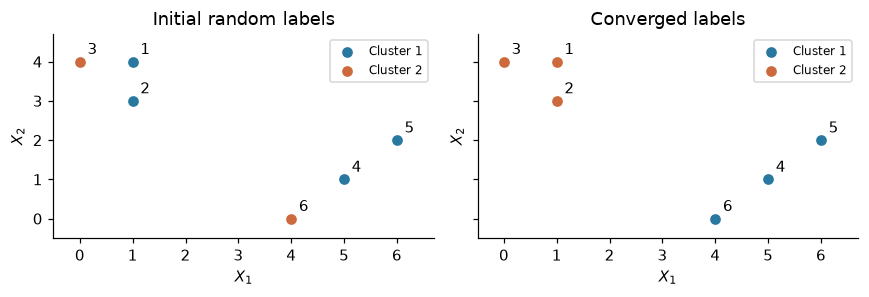

In [9]:
points = np.array([[1, 4], [1, 3], [0, 4], [5, 1], [6, 2], [4, 0]])
manual_labels = np.random.default_rng(SEED).integers(1, 3, size=6)
initial_labels = manual_labels.copy()
steps = []
for step in range(10):
    centers = np.array([points[manual_labels == k].mean(axis=0) for k in (1, 2)])
    steps.append({'Step': step, 'Labels (observations 1-6)': ' '.join(map(str, manual_labels)),
                  'Centroid 1': tuple(centers[0].round(3)),
                  'Centroid 2': tuple(centers[1].round(3))})
    updated = ((points[:, None] - centers)**2).sum(axis=2).argmin(axis=1) + 1
    if np.array_equal(updated, manual_labels):
        break
    manual_labels = updated
display(pd.DataFrame(steps))
print('Next assignment is unchanged:', ' '.join(map(str, updated)))
assert np.array_equal(manual_labels, [2, 2, 2, 1, 1, 1])

fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharex=True, sharey=True)
for ax, labels, title in zip(axes, [initial_labels, manual_labels],
                           ['Initial random labels', 'Converged labels']):
    for k, color in [(1, '#2878a0'), (2, '#cc693d')]:
        ax.scatter(*points[labels == k].T, color=color, label=f'Cluster {k}')
    for i, point in enumerate(points, 1):
        ax.annotate(str(i), point, xytext=(5, 5), textcoords='offset points')
    ax.set(xlabel='$X_1$', ylabel='$X_2$', title=title, xlim=(-.5, 6.7), ylim=(-.5, 4.7))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### ISLR 12.6.4: linkage heights

**(a)** For $A=\{1,2,3\}$ and $B=\{4,5\}$, complete linkage merges at $\max_{i\in A,j\in B}d_{ij}$, while single linkage merges at $\min_{i\in A,j\in B}d_{ij}$. The complete-linkage fusion is at least as high; equality is possible if all cross-cluster dissimilarities are equal.

**(b)** For singletons $\{5\}$ and $\{6\}$, both heights equal $d_{56}$.

### ISLR 12.6.5: shopper scaling

In Figure 12.16 (p. 528), I expect these $K=2$ results:

- **Raw counts:** the shopper buying 11 pairs of socks forms one cluster, and the other seven shoppers form the second. This split minimizes within-cluster squared distance; sock counts dominate the 0/1 computer counts.
- **Standardized variables:** the four computer buyers (5, 6, 7, and 8 pairs of socks) form one cluster, and the four non-buyers (6, 7, 8, and 11 pairs) form the other. Both variables contribute, but this is the lowest-error split for the plotted shoppers.
- **Dollars spent:** the same buyers-versus-non-buyers split results. Computer spending is much larger than sock spending and dominates distance.

Thus the units determine which shopping behavior drives clustering. Different initializations can still give different local solutions.

### ISLR 12.6.6: recover loadings by regression

For centered $X$, fix the score matrix $Z\in\mathbb R^{n\times M}$. Objective (12.6) separates by feature:
$$\sum_{j=1}^p\left\|x_j-Z\phi_j\right\|^2.$$
For each $j$, regress feature vector $x_j$ on the $M$ score vectors, without an intercept. The $M$ fitted coefficients form row $j$ of the loading matrix:
$$\widehat\phi_j=(Z^\top Z)^{-1}Z^\top x_j,\qquad
\widehat\phi_{jm}=\frac{z_m^\top x_j}{z_m^\top z_m}.$$
The second equality uses the orthogonality of principal-component scores. Thus $p$ separate regressions recover all $M$ loading vectors, assuming the retained components have positive variance. Since the responses and scores are centered, including an intercept would give zero.


### ISLR 12.6.7: correlation and Euclidean distance

For row-standardized observations $z_i,z_j$ with $p$ features and sample standard deviation one,
$\sum_k z_{ik}^2=p-1$ and $r_{ij}=z_i^Tz_j/(p-1)$. Therefore,

$$\|z_i-z_j\|^2=2(p-1)-2z_i^Tz_j=2(p-1)(1-r_{ij}).$$

For the four variables in `USArrests`, the constant is **6**. I standardize **rows** here; the following exercises standardize feature columns. I use the original R dataset, including its original urban-population values, from the [Rdatasets CSV](https://vincentarelbundock.github.io/Rdatasets/csv/datasets/USArrests.csv). See the [R documentation](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/USArrests.html) for variable definitions.

In [10]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits

arrests = pd.read_csv('data/USArrests.csv', index_col=0)
assert arrests.shape == (50, 4) and not arrests.isna().any().any()
arrests_rows = arrests.to_numpy()
arrests_rows = ((arrests_rows - arrests_rows.mean(axis=1, keepdims=True))
                / arrests_rows.std(axis=1, ddof=1, keepdims=True))
arrests_d2 = pdist(arrests_rows, metric='sqeuclidean')
arrests_cor = pdist(arrests_rows, metric='correlation')
assert np.allclose(arrests_d2, 6 * arrests_cor)
print(f'All 1,225 state pairs: max |d² - 6(1-r)| = '
      f'{np.max(np.abs(arrests_d2 - 6 * arrests_cor)):.2e}')

All 1,225 state pairs: max |d² - 6(1-r)| = 2.37e-15


### ISLR 12.6.8: two calculations of PVE

I center and scale each variable using its sample standard deviation. **(a)** The PCA standard deviations are the square roots of the eigenvalues, so PVE is $s_m^2/\sum_\ell s_\ell^2$. **(b)** With loading vector $\phi_m$ and centered, scaled matrix $X$, Equation 12.10 gives $\mathrm{PVE}_m=\|X\phi_m\|^2/\|X\|_F^2$. Both calculations below use exactly the same matrix.

In [11]:
arrests_scaled = (arrests - arrests.mean()) / arrests.std(ddof=1)
arrests_pca = PCA(svd_solver='full').fit(arrests_scaled)
arrests_sdev = np.sqrt(arrests_pca.explained_variance_)
arrests_pve_a = arrests_sdev**2 / np.sum(arrests_sdev**2)
arrests_scores = arrests_scaled.to_numpy() @ arrests_pca.components_.T
arrests_pve_b = (arrests_scores**2).sum(axis=0) / (arrests_scaled.to_numpy()**2).sum()
assert np.allclose(arrests_pve_a, arrests_pve_b)
display(pd.DataFrame({'PCA SD': arrests_sdev, 'PVE (a)': arrests_pve_a,
                      'PVE (b)': arrests_pve_b}, index=['PC1', 'PC2', 'PC3', 'PC4']).round(6))

,PCA SD,PVE (a),PVE (b)
PC1,1.574878,0.620060,0.620060
PC2,0.994869,0.247441,0.247441
PC3,0.597129,0.089141,0.089141
PC4,0.416449,0.043358,0.043358


### ISLR 12.6.9: hierarchical clustering of states

**(a)-(c)** I use complete linkage and Euclidean distance before and after scaling columns. Each dashed line lies between the merge heights that leave three and two clusters. The dendrograms use postal abbreviations; the table lists all state memberships.

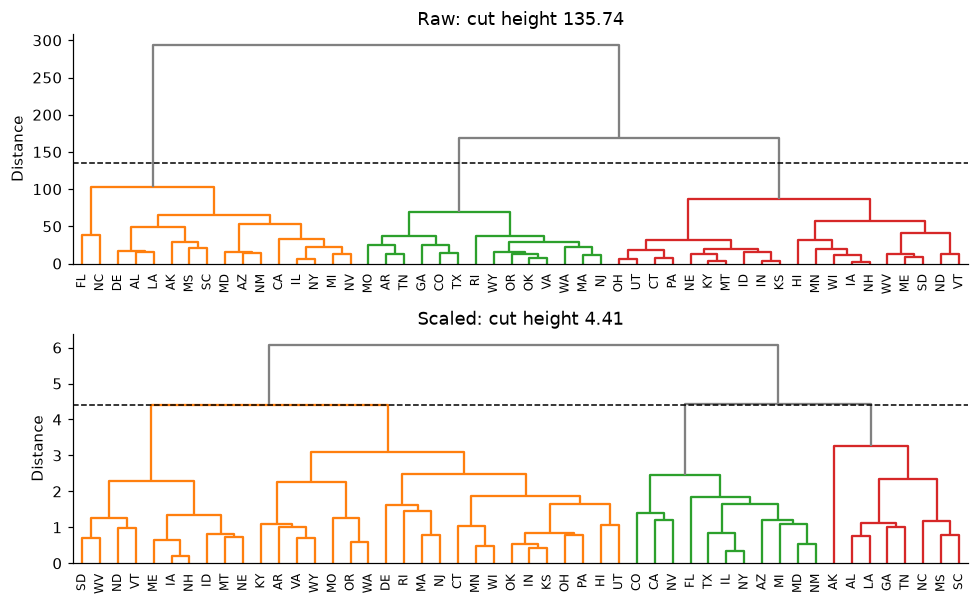

Count  \
Data   Cluster          
Raw    1           16   
       2           14   
       3           20   
Scaled 1           31   
       2           11   
       3            8   

                                                                                                                                                                                                                                                                                                                                          States  
Data   Cluster                                                                                                                                                                                                                                                                                                                                    
Raw    1                                                                                                                                                             Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina  
       2                                                                                                                                                                                       Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming  
       3                                                                                                                                Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin  
Scaled 1        Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming  
       2                                                                                                                                                                                                                               Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas  
       3                                                                                                                                                                                                                                             Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee

Raw/scaled partition ARI: 0.368


In [12]:
arrests_abbrev = ('AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI '
                  'MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX '
                  'UT VT VA WA WV WI WY').split()
arrests_linkages = {}
arrests_groups = {}
arrests_members = []
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6))
for ax, (name, values) in zip(axes, [('Raw', arrests), ('Scaled', arrests_scaled)]):
    tree = linkage(values, method='complete', metric='euclidean')
    cut = (tree[-3, 2] + tree[-2, 2]) / 2
    labels = fcluster(tree, cut, criterion='distance')
    assert len(np.unique(labels)) == 3
    arrests_linkages[name], arrests_groups[name] = tree, labels
    dendrogram(tree, labels=arrests_abbrev, leaf_rotation=90, leaf_font_size=8,
               color_threshold=cut, above_threshold_color='gray', ax=ax)
    ax.axhline(cut, color='black', linestyle='--', linewidth=1)
    ax.set(title=f'{name}: cut height {cut:.2f}', ylabel='Distance')
    for group in range(1, 4):
        states = arrests.index[labels == group].tolist()
        arrests_members.append({'Data': name, 'Cluster': group, 'Count': len(states),
                                'States': ', '.join(states)})
fig.tight_layout()
plt.show()
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(arrests_members).set_index(['Data', 'Cluster']))
print('Raw/scaled partition ARI:', round(adjusted_rand_score(
    arrests_groups['Raw'], arrests_groups['Scaled']), 4))

**(d)** Scaling changes the memberships (raw/scaled ARI = 0.368), rather than merely rescaling the dendrogram heights. In the raw data, Assault has the largest numerical spread and dominates Euclidean distance. I would scale these variables because they have different units and ranges, and I have no reason to assign larger weight to a variable solely because of its units. Standardization gives each variable equal marginal variance; it does not make their information independent.

### ISLR 12.6.10: simulated classes, PCA, and k-means

**(a)-(b)** I generate 20 observations per class and 50 independent Gaussian noise features with standard deviation one. Class means are $(-1.5,-1.5)$, $(1.5,-1.5)$, and $(0,1.5)$ for the first and second blocks of 25 features. The first two PC scores show clear separation of the three classes.

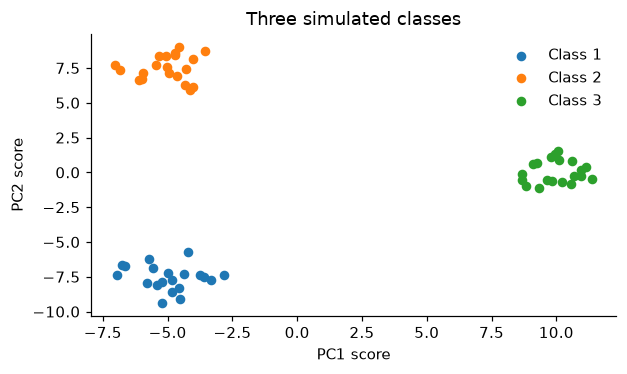

PVE of PC1 and PC2: [0.3793 0.2879]


In [13]:
sim_rng = np.random.default_rng(SEED)
sim_truth = np.repeat([1, 2, 3], 20)
sim_means = np.repeat([[-1.5, -1.5], [1.5, -1.5], [0, 1.5]], 25, axis=1)
sim_X = sim_rng.normal(size=(60, 50)) + sim_means[sim_truth - 1]
sim_pca = PCA(n_components=2, svd_solver='full').fit(sim_X)
sim_scores = sim_pca.transform(sim_X)
fig, ax = plt.subplots(figsize=(5.8, 3.5))
for group, color in zip([1, 2, 3], ['tab:blue', 'tab:orange', 'tab:green']):
    ax.scatter(*sim_scores[sim_truth == group].T, label=f'Class {group}',
               color=color, s=28)
ax.set(xlabel='PC1 score', ylabel='PC2 score', title='Three simulated classes')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print('PVE of PC1 and PC2:', np.round(sim_pca.explained_variance_ratio_, 4))

**(c)-(g)** I use 20 initializations per fit, with seed 552. Cluster numbers are arbitrary, so I compare the partitions using cross-tabulations and adjusted Rand index (ARI), which equals one for identical partitions up to relabeling.

In [14]:
sim_scaled = (sim_X - sim_X.mean(axis=0)) / sim_X.std(axis=0, ddof=1)
sim_settings = [('Raw, K=3', sim_X, 3), ('Raw, K=2', sim_X, 2),
                ('Raw, K=4', sim_X, 4), ('PC1-PC2, K=3', sim_scores, 3),
                ('Scaled, K=3', sim_scaled, 3)]
sim_tables, sim_agreement = {}, []
with threadpool_limits(limits=1):
    for name, values, k in sim_settings:
        labels = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(values) + 1
        sim_tables[name] = pd.crosstab(pd.Series(sim_truth, name='True class'),
                                      pd.Series(labels, name='Cluster'))
        sim_agreement.append({'Fit': name, 'ARI': adjusted_rand_score(sim_truth, labels)})
display(pd.concat(sim_tables, names=['Fit']).fillna(0).astype(int))
display(pd.DataFrame(sim_agreement).set_index('Fit').round(4))

Cluster                   1   2   3   4
Fit          True class                
Raw, K=3     1           20   0   0   0
             2            0  20   0   0
             3            0   0  20   0
Raw, K=2     1            0  20   0   0
             2            0  20   0   0
             3           20   0   0   0
Raw, K=4     1            0   0   6  14
             2            0  20   0   0
             3           20   0   0   0
PC1-PC2, K=3 1           20   0   0   0
             2            0  20   0   0
             3            0   0  20   0
Scaled, K=3  1           20   0   0   0
             2            0  20   0   0
             3            0   0  20   0

,ARI
Fit,
"Raw, K=3",1.0000
"Raw, K=2",0.5630
"Raw, K=4",0.8869
"PC1-PC2, K=3",1.0000
"Scaled, K=3",1.0000


**Results.** With $K=3$, raw features, two PC scores, and standardized features all recover the three classes exactly. With $K=2$, classes 1 and 2 merge (ARI 0.5630). With $K=4$, class 1 splits into groups of 6 and 14, while the other classes remain intact (ARI 0.8869). The scaled-data result agrees with the separation visible in (b): the mean shifts are strong and the variables have comparable scales. These favorable results describe this simulation, not a general guarantee that scaling or using two PCs preserves clusters.

### ISLR 12.6.11: matrix completion

I implement Algorithm 12.1 with column-mean initialization and rank-$M$ approximations. Observed entries stay fixed; only missing entries are replaced. Following the lab, the stopping statistic is
$$r_t=\frac{\operatorname{MSE}_{O,t-1}-\operatorname{MSE}_{O,t}}{\operatorname{mean}_{O}(X_{ij}^2)}.$$
The function records the iteration, observed-entry MSE, and relative improvement; `verbose=True` prints progress. I stop at $r_t\le10^{-6}$ or 2,000 iterations.

The [Boston data](https://github.com/intro-stat-learning/ISLP/blob/main/ISLP/data/Boston.csv) have 506 rows and 13 columns, matching the ISLR2 version. All columns, including `medv`, are variables in this unsupervised exercise. I standardize the complete matrix using sample standard deviations, as requested, then mask entries. Each repetition uses one random permutation, so the 5%, 10%, ..., 30% masks are nested and identical across ranks. Error is RMSE on the masked entries in standardized units, averaged over ten repetitions.

missing %,5,10,15,20,25,30
rank,,,,,,
1,0.733,0.777,0.764,0.771,0.764,0.775
2,0.712,0.756,0.751,0.766,0.772,0.788
3,0.678,0.732,0.742,0.781,0.883,0.881
4,1.576,1.610,1.477,1.599,1.655,1.735
5,1.870,1.850,1.848,1.869,1.939,2.121
6,1.691,1.771,1.901,2.101,2.262,2.204
7,1.712,1.821,1.945,2.054,2.093,2.223
8,1.971,2.132,2.303,2.172,2.145,2.103


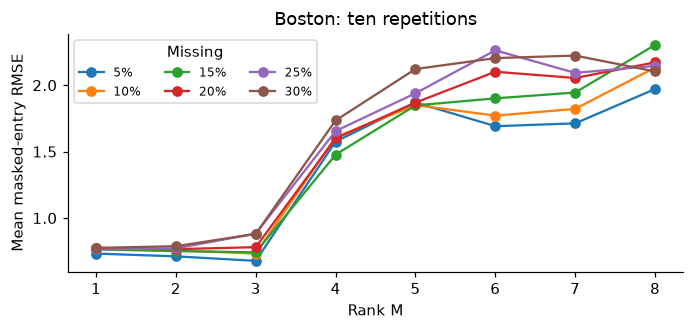

Converged: **480/480** fits; maximum iterations: **1657**.

In [15]:
from scipy.cluster.hierarchy import cut_tree
from scipy.stats import ttest_ind

def complete_matrix(X, rank, tol=1e-6, max_iter=2000, verbose=False,
                    approximation=None):
    X = np.asarray(X, dtype=float)
    missing = np.isnan(X)
    observed = ~missing
    means = np.nanmean(X, axis=0)
    if not np.isfinite(means).all() or not 1 <= rank < min(X.shape):
        raise ValueError('Each column needs observations and rank must be valid.')
    filled = np.where(missing, means, X)
    scale = max(np.mean(X[observed] ** 2), np.finfo(float).eps)
    previous = np.mean((X - means)[observed] ** 2)
    history = []
    for iteration in range(1, max_iter + 1):
        if approximation is None:
            U, s, Vt = np.linalg.svd(filled, full_matrices=False)
            fitted = (U[:, :rank] * s[:rank]) @ Vt[:rank]
        else:
            fitted = approximation(filled, rank)
        filled[missing] = fitted[missing]
        mse = np.mean((X[observed] - fitted[observed]) ** 2)
        relative = (previous - mse) / scale
        history.append((iteration, mse, relative))
        if verbose:
            print(f'{iteration}: MSE={mse:.6f}, relative={relative:.3g}')
        if relative <= tol:
            break
        previous = mse
    assert np.array_equal(filled[observed], X[observed])
    history = pd.DataFrame(history, columns=['iteration', 'observed MSE', 'relative'])
    return filled, history

completion_boston = pd.read_csv('data/Boston.csv')
assert completion_boston.shape == (506, 13)
completion_X = ((completion_boston - completion_boston.mean()) /
                completion_boston.std(ddof=1)).to_numpy()
completion_rows = []
with threadpool_limits(limits=1):
    for repetition in range(10):
        order = np.random.default_rng(SEED + repetition).permutation(completion_X.size)
        previous_mask = np.zeros(completion_X.shape, dtype=bool)
        for percent in range(5, 31, 5):
            mask = np.zeros(completion_X.size, dtype=bool)
            mask[order[:int(completion_X.size * percent / 100)]] = True
            mask = mask.reshape(completion_X.shape)
            assert np.all(mask[previous_mask])
            previous_mask = mask.copy()
            incomplete = completion_X.copy()
            incomplete[mask] = np.nan
            for rank in range(1, 9):
                filled, history = complete_matrix(incomplete, rank)
                rmse = np.sqrt(np.mean((filled[mask] - completion_X[mask]) ** 2))
                completion_rows.append((repetition, percent, rank, rmse,
                                        len(history), history['relative'].iloc[-1] <= 1e-6))
completion_results = pd.DataFrame(completion_rows, columns=[
    'repetition', 'missing %', 'rank', 'RMSE', 'iterations', 'converged'])
completion_mean = completion_results.pivot_table(index='rank', columns='missing %', values='RMSE')
display(completion_mean.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.1))
for percent in completion_mean.columns:
    ax.plot(completion_mean.index, completion_mean[percent], marker='o', label=f'{percent}%')
ax.set(xlabel='Rank M', ylabel='Mean masked-entry RMSE', title='Boston: ten repetitions')
ax.legend(title='Missing', ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
display(Markdown(f"Converged: **{completion_results['converged'].sum()}/480** fits; "
                 f"maximum iterations: **{completion_results['iterations'].max()}**."))

Rank 3 has the lowest mean RMSE at 5-15% missingness, rank 2 at 20%, and rank 1 at 25-30%. Ranks 4-8 perform substantially worse. Higher rank can fit the observed entries more closely while extrapolating poorly to missing values; the masked-entry RMSE is the relevant comparison. The complete matrix is used only for the specified initial scaling and final error calculation.

### ISLR 12.6.12: matrix completion using PCA

The lab's SVD is uncentered, whereas scikit-learn's `PCA` automatically centers its input. To obtain the same rank-$M$ approximation, I fit PCA to the mirrored rows $[A;-A]$, whose mean is zero and whose cross-product is $2A^TA$. Its loading vectors therefore give the same approximation $AV_MV_M^T$. This is the Python equivalent of using `prcomp(..., center=FALSE, scale.=FALSE)`. The wrapper below uses PCA at every iteration.

In [16]:
def pca_approximation(A, rank):
    pca = PCA(n_components=rank, svd_solver='full')
    pca.fit(np.vstack([A, -A]))
    return (A @ pca.components_.T) @ pca.components_

def complete_pca(X, rank, tol=1e-6, max_iter=2000, verbose=False):
    return complete_matrix(X, rank, tol, max_iter, verbose,
                           approximation=pca_approximation)

completion_check = completion_X.copy()
completion_mask = np.zeros(completion_X.size, dtype=bool)
completion_mask[np.random.default_rng(SEED).permutation(completion_X.size)
                [:int(.10 * completion_X.size)]] = True
completion_mask = completion_mask.reshape(completion_X.shape)
completion_check[completion_mask] = np.nan
with threadpool_limits(limits=1):
    completion_svd, completion_h1 = complete_matrix(completion_check, rank=3)
    completion_pca, completion_h2 = complete_pca(completion_check, rank=3)
assert np.allclose(completion_svd, completion_pca, atol=1e-8)
print('SVD/PCA iterations:', len(completion_h1), len(completion_h2))
print('Largest absolute difference:', f'{np.max(np.abs(completion_svd-completion_pca)):.2e}')
display(completion_h2.tail(3).round(8))

SVD/PCA iterations: 20 20
Largest absolute difference: 8.88e-15


,iteration,observed MSE,relative
17,18,0.281032,1.290000e-06
18,19,0.281030,1.090000e-06
19,20,0.281030,9.200000e-07


### ISLR 12.6.13: gene expression

**(a)** I load the [book's data](https://www.statlearning.com/s/Ch12Ex13.csv) without a header. Rows are genes and columns are the 40 samples, so I transpose before clustering. Samples 1-20 are healthy and 21-40 are diseased.

**(b)** I use $d(i,j)=1-\operatorname{cor}(x_i,x_j)$ across the 1,000 genes and compare complete, average, and single linkage. Each tree is cut into two clusters. The adjusted Rand index (ARI) compares clusters to disease groups without depending on the arbitrary cluster numbers. Leaves marked H/D indicate the known groups; these labels are not used for clustering.

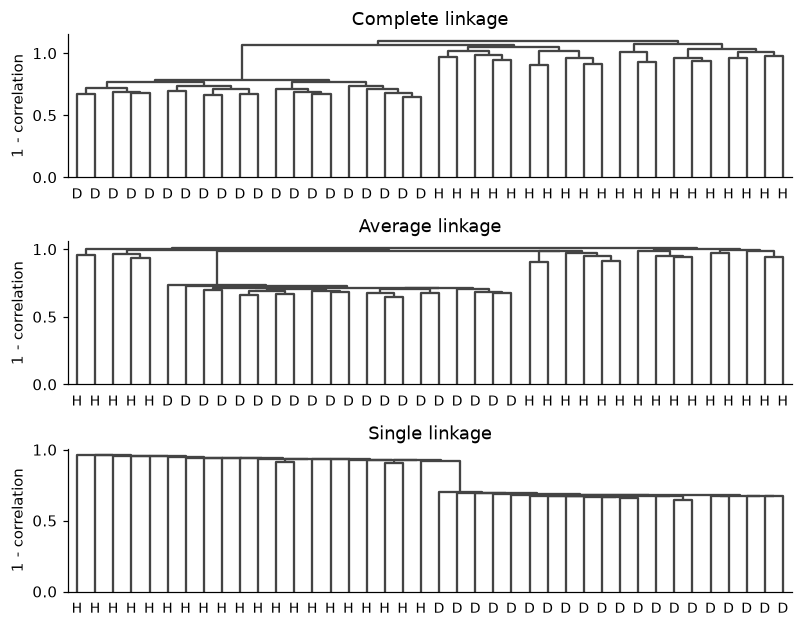

Cluster             1   2
Linkage  Group           
complete Diseased   0  20
         Healthy   10  10
average  Diseased   0  20
         Healthy    9  11
single   Diseased  20   0
         Healthy   19   1

,Linkage,ARI
0,complete,0.2353
1,average,0.1880
2,single,0.0000


In [17]:
gene_data = pd.read_csv('data/Ch12Ex13.csv', header=None)
assert gene_data.shape == (1000, 40) and not gene_data.isna().any().any()
gene_samples = gene_data.to_numpy().T
gene_groups = np.repeat(['Healthy', 'Diseased'], 20)
gene_distance = pdist(gene_samples, metric='correlation')
gene_labels = ['H'] * 20 + ['D'] * 20
gene_tables = []
gene_scores = []
fig, axes = plt.subplots(3, 1, figsize=(7.4, 5.8))
for ax, method in zip(axes, ['complete', 'average', 'single']):
    tree = linkage(gene_distance, method=method)
    clusters = cut_tree(tree, n_clusters=2).ravel() + 1
    dendrogram(tree, labels=gene_labels, leaf_rotation=0, leaf_font_size=9,
               color_threshold=0, above_threshold_color='#444444', ax=ax)
    ax.set(title=f'{method.capitalize()} linkage', ylabel='1 - correlation')
    gene_tables.append(pd.crosstab(pd.Series(gene_groups, name='Group'),
                                  pd.Series(clusters, name='Cluster')))
    gene_scores.append((method, adjusted_rand_score(gene_groups, clusters)))
plt.tight_layout()
plt.show()
display(pd.concat(gene_tables, keys=['complete', 'average', 'single'], names=['Linkage']))
display(pd.DataFrame(gene_scores, columns=['Linkage', 'ARI']).round(4))

The groups are not perfectly separated by any linkage. Complete linkage has the highest ARI (0.2353), followed by average (0.1880); single linkage produces a 39-sample cluster and a singleton (ARI 0). Thus the results depend on linkage, and correlation clustering only weakly recovers the known groups.

**(c)** To find genes that differ most in magnitude, I rank the absolute difference between the diseased and healthy means. I also report Welch two-sample $t$-test p-values and Benjamini-Hochberg adjusted values across all 1,000 genes; these separate effect size from sampling uncertainty. Gene numbers below are one-based row numbers, since names are not supplied. These are exploratory associations, not evidence of causation.

In [18]:
gene_healthy = gene_data.iloc[:, :20].to_numpy()
gene_diseased = gene_data.iloc[:, 20:].to_numpy()
gene_difference = gene_diseased.mean(axis=1) - gene_healthy.mean(axis=1)
gene_p = ttest_ind(gene_diseased, gene_healthy, axis=1, equal_var=False).pvalue
# Benjamini-Hochberg adjustment, restored to the original gene order.
gene_order = np.argsort(gene_p)
gene_q_sorted = np.minimum.accumulate(
    (gene_p[gene_order] * len(gene_p) / np.arange(1, len(gene_p)+1))[::-1])[::-1]
gene_q = np.empty_like(gene_p)
gene_q[gene_order] = np.minimum(gene_q_sorted, 1)
gene_ranking = pd.DataFrame({'Gene': np.arange(1, 1001),
    'Healthy mean': gene_healthy.mean(axis=1), 'Diseased mean': gene_diseased.mean(axis=1),
    'Difference': gene_difference, 'p-value': gene_p, 'BH q-value': gene_q})
gene_top = gene_ranking.iloc[np.argsort(-np.abs(gene_difference))[:10]]
gene_display = gene_top.round(3).reset_index(drop=True)
for column in ['p-value', 'BH q-value']:
    gene_display[column] = gene_top[column].map('{:.2e}'.format).to_numpy()
display(gene_display)
print('Genes with BH q < 0.05:', int((gene_q < .05).sum()))

,Gene,Healthy mean,Diseased mean,Difference,p-value,BH q-value
0,600,-0.648,2.100,2.748,1.00e-11,3.35e-09
1,584,-0.313,2.289,2.602,2.13e-09,2.67e-07
2,549,-0.327,2.224,2.551,7.03e-08,1.50e-06
3,540,-0.207,2.338,2.545,1.38e-08,5.32e-07
4,502,-0.242,2.303,2.544,1.53e-12,1.53e-09
5,568,-0.263,2.257,2.519,6.34e-08,1.41e-06
6,582,-0.247,2.249,2.496,1.64e-07,3.09e-06
7,565,-0.133,2.338,2.471,1.77e-10,3.53e-08
8,562,-0.438,2.027,2.466,1.71e-08,5.53e-07
9,554,-0.257,2.180,2.437,4.67e-09,3.89e-07


Genes with BH q < 0.05: 117


Gene 600 has the largest mean difference (2.748), followed by genes 584 and 549. The top ten all have higher mean expression in the diseased group. Across all 1,000 genes, 117 have BH-adjusted values below 0.05.